        variable    n  skew  shapiro_W   p normal?
       Valuation 1037 11.57      0.253 0.0      no
         log_val 1037  1.48      0.848 0.0      no
Total Raised (M) 1013  4.67      0.539 0.0      no
      log_raised 1013 -2.29      0.839 0.0      no
 Investors Count 1036  2.13      0.848 0.0      no
      Deal Terms 1008  1.66      0.830 0.0      no


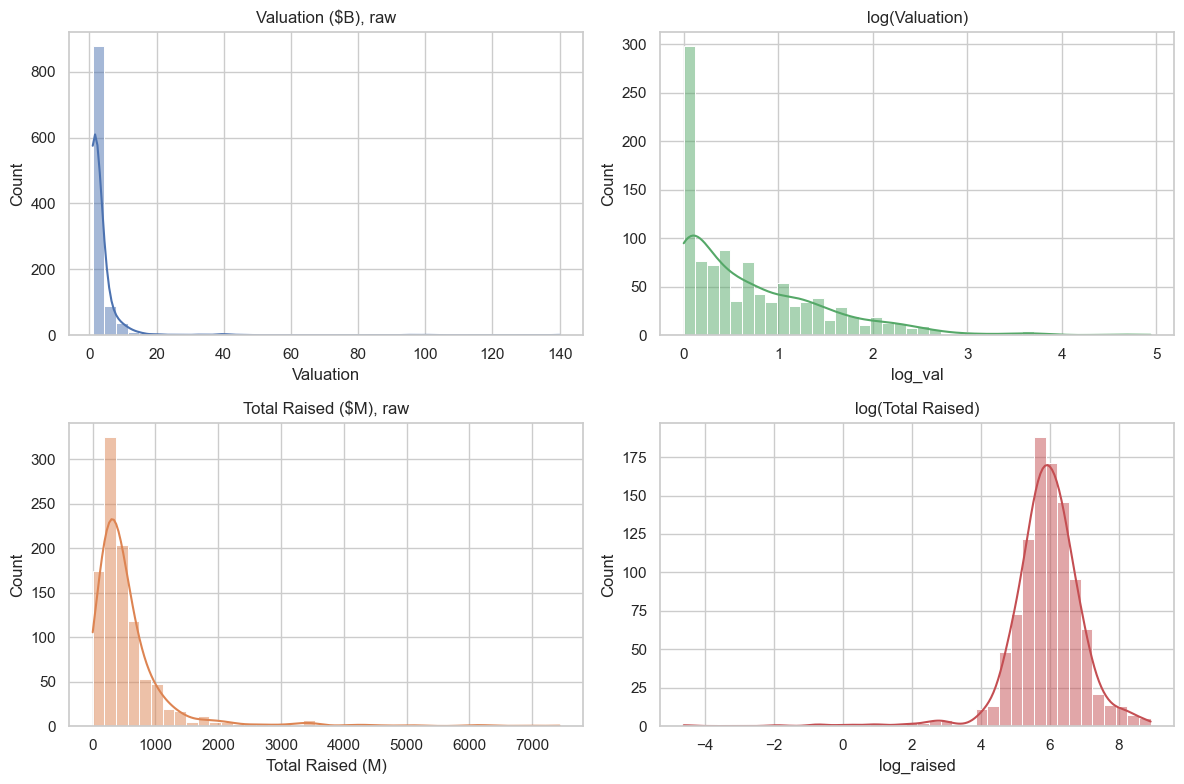

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("../results/plots", exist_ok=True)

df = pd.read_csv("../data/Unicorn_Companies_cleaned.csv")
df["log_val"] = np.log(df["Valuation"])
df["log_raised"] = np.log(df["Total Raised (M)"])

# Normality tests: raw vs log (Shapiro-Wilk on a 500-row sample, since it is sensitive at large n)
cols = ["Valuation", "log_val", "Total Raised (M)", "log_raised", "Investors Count", "Deal Terms"]
rows = []
for c in cols:
    x = df[c].dropna()
    s = x.sample(min(500, len(x)), random_state=1)
    stat, p = stats.shapiro(s)
    rows.append({"variable": c, "n": len(x), "skew": round(x.skew(), 2), "shapiro_W": round(stat, 3), "p": round(p, 4),
                 "normal?": "yes" if p > 0.05 else "no"})
print(pd.DataFrame(rows).to_string(index=False))

# Raw vs log distributions
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(df["Valuation"], bins=40, kde=True, ax=axes[0, 0]); axes[0, 0].set_title("Valuation ($B), raw")
sns.histplot(df["log_val"], bins=40, kde=True, ax=axes[0, 1], color="#55A868"); axes[0, 1].set_title("log(Valuation)")
sns.histplot(df["Total Raised (M)"].dropna(), bins=40, kde=True, ax=axes[1, 0], color="#DD8452"); axes[1, 0].set_title("Total Raised ($M), raw")
sns.histplot(df["log_raised"].dropna(), bins=40, kde=True, ax=axes[1, 1], color="#C44E52"); axes[1, 1].set_title("log(Total Raised)")
plt.tight_layout()
plt.savefig("../results/plots/03_univariate_distributions.png", dpi=150)
plt.show()

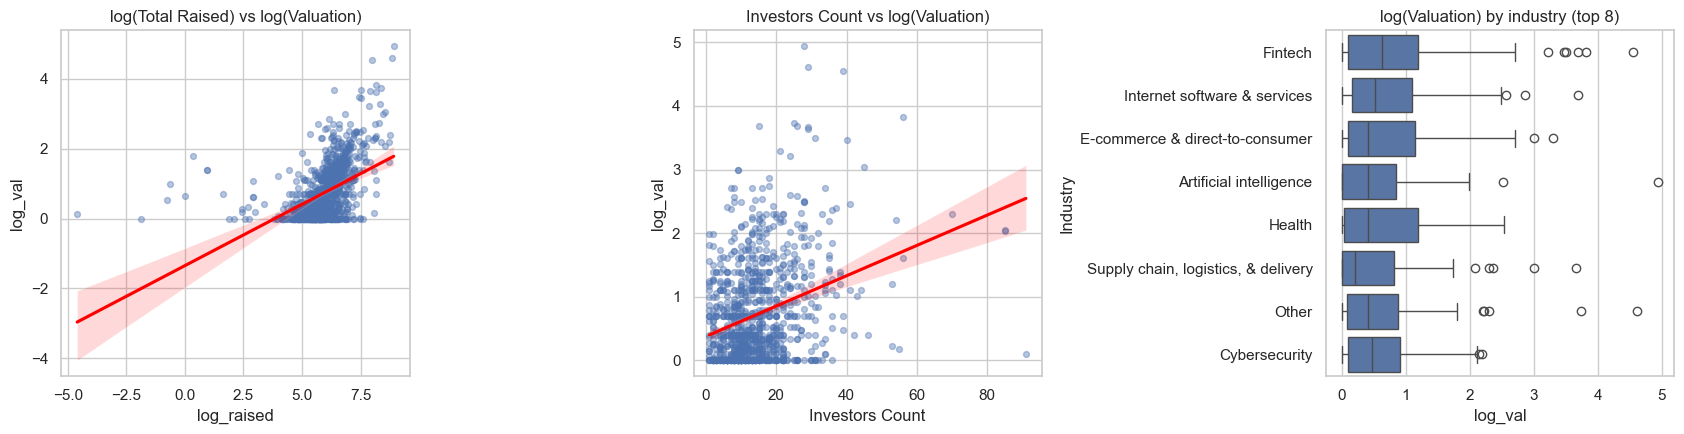

              Company  Valuation  Total Raised (M)        Country
733             Elemy       1.15              0.01  United States
933  Pantheon Systems       1.00              0.15  United States
485              Wave       1.70              0.46        Senegal
418             Ethos       2.70              0.52  United States
461            eDaili       1.90              1.00          China


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# Numeric vs numeric: raised vs valuation (log-log), with trend
sns.regplot(data=df, x="log_raised", y="log_val", scatter_kws={"alpha": 0.4, "s": 18},
            line_kws={"color": "red"}, ax=axes[0])
axes[0].set_title("log(Total Raised) vs log(Valuation)")

# Numeric vs numeric: investors count
sns.regplot(data=df, x="Investors Count", y="log_val", scatter_kws={"alpha": 0.4, "s": 18},
            line_kws={"color": "red"}, ax=axes[1])
axes[1].set_title("Investors Count vs log(Valuation)")

# Numeric vs categorical: valuation by top industries
top = df["Industry"].value_counts().head(8).index
sns.boxplot(data=df[df["Industry"].isin(top)], y="Industry", x="log_val", ax=axes[2], order=top)
axes[2].set_title("log(Valuation) by industry (top 8)")

plt.tight_layout()
plt.savefig("../results/plots/03_bivariate.png", dpi=150)
plt.show()

# Check the suspiciously small Total Raised values
print(df.nsmallest(5, "Total Raised (M)")[["Company", "Valuation", "Total Raised (M)", "Country"]])

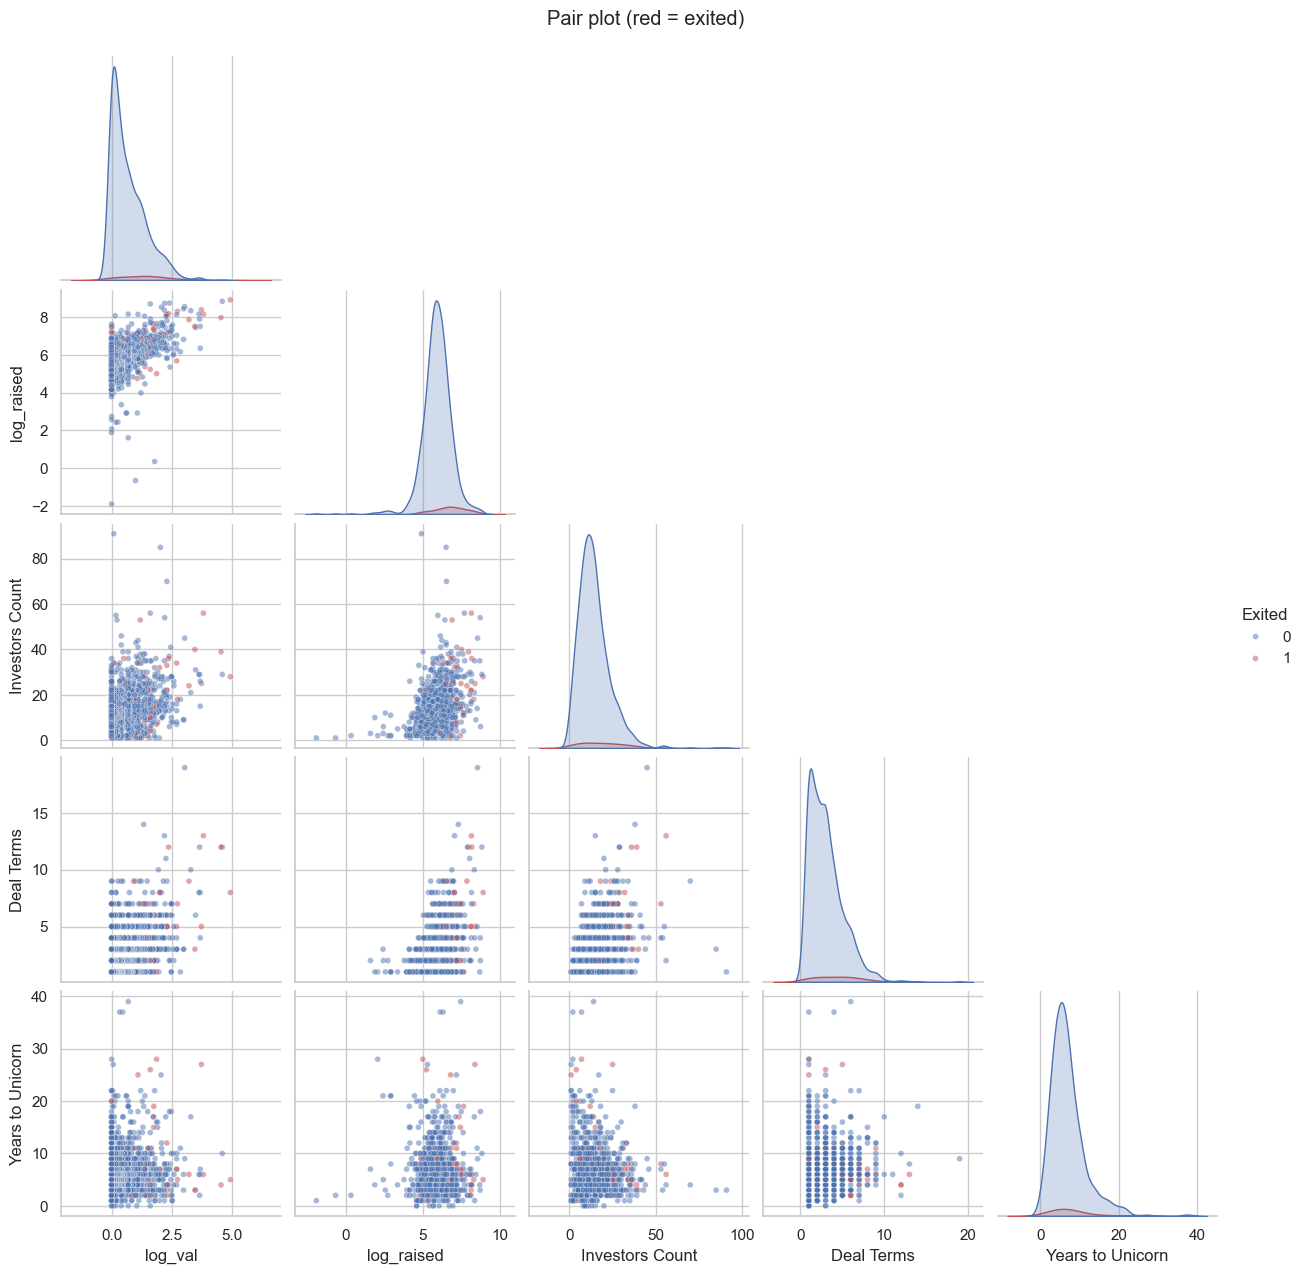

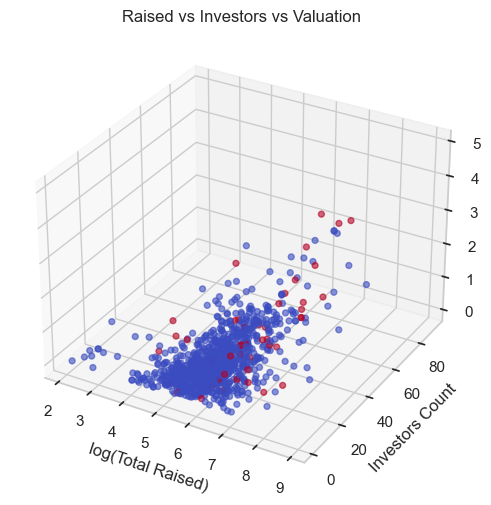

In [3]:
# Pair plot of key variables
pp_cols = ["log_val", "log_raised", "Investors Count", "Deal Terms", "Years to Unicorn"]
sample = df[pp_cols + ["Exited"]].copy()
sample = sample[sample["Years to Unicorn"] < 40]
g = sns.pairplot(sample, hue="Exited", corner=True, plot_kws={"alpha": 0.5, "s": 18},
                 palette={0: "#4C72B0", 1: "#C44E52"})
g.fig.suptitle("Pair plot (red = exited)", y=1.02)
g.savefig("../results/plots/03_pairplot.png", dpi=120)
plt.show()

# 3D scatter: raised, investors, valuation
from mpl_toolkits.mplot3d import Axes3D
d3 = df.dropna(subset=["log_raised", "Investors Count", "log_val"])
d3 = d3[d3["log_raised"] > 2]
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
sc = ax.scatter(d3["log_raised"], d3["Investors Count"], d3["log_val"],
                c=d3["Exited"], cmap="coolwarm", alpha=0.6, s=18)
ax.set_xlabel("log(Total Raised)")
ax.set_ylabel("Investors Count")
ax.set_zlabel("log(Valuation)")
ax.set_title("Raised vs Investors vs Valuation")
plt.savefig("../results/plots/03_3d_scatter.png", dpi=130)
plt.show()

In [4]:
print("KEY FINDINGS (Notebook 3)")
print("- All variables fail Shapiro-Wilk; log(Total Raised) becomes near-bell-shaped (skew 4.67 -> -2.29)")
print("- log(Valuation) still right-skewed (1.48): hard floor at $1B")
print("- Total Raised is the clearest valuation driver; Investors Count is weak")
print("- Industry boxplots overlap heavily (consistent with null ANOVA)")
print("- Exited companies cluster at high raised / many investors / high valuation")
print("- Elemy ($0.01M raised) looks like a unit error; treat Total Raised < $5M as unreliable")

KEY FINDINGS (Notebook 3)
- All variables fail Shapiro-Wilk; log(Total Raised) becomes near-bell-shaped (skew 4.67 -> -2.29)
- log(Valuation) still right-skewed (1.48): hard floor at $1B
- Total Raised is the clearest valuation driver; Investors Count is weak
- Industry boxplots overlap heavily (consistent with null ANOVA)
- Exited companies cluster at high raised / many investors / high valuation
- Elemy ($0.01M raised) looks like a unit error; treat Total Raised < $5M as unreliable
